In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score, confusion_matrix

## Part A: Binomial simulation and conditional probability

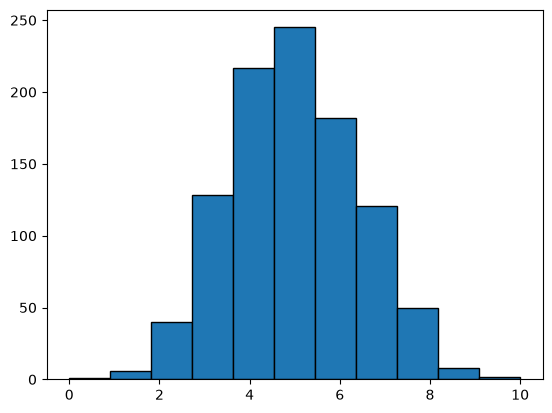

np.float64(0.245)

In [2]:
np.random.seed(0)
flips = np.random.binomial(10, 0.5, 1000)
plt.hist(flips, bins=11, edgecolor='black')
plt.show()
emp_prob_5 = np.mean(flips == 5)
emp_prob_5

In [3]:
titanic = sns.load_dataset('titanic')

In [4]:
p_survived_given_female = (len(titanic[(titanic.sex=='female') & (titanic.survived==1)]) / len(titanic[titanic.sex=='female']))
p_female_given_survived = (len(titanic[(titanic.sex=='female') & (titanic.survived==1)]) / len(titanic[titanic.survived==1]))
p_survived_given_female, p_female_given_survived

(0.7420382165605095, 0.6812865497076024)

## Part B: Naive Bayes classifier

In [5]:
df = titanic.dropna(subset=['sex','age','class','survived']).copy()
le1, le2 = LabelEncoder(), LabelEncoder()
df['sex_enc'] = le1.fit_transform(df['sex'])
df['class_enc'] = le2.fit_transform(df['class'])
X = df[['sex_enc','age','class_enc']]
y = df['survived']
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.2,random_state=0)

In [6]:
nb = GaussianNB().fit(X_train, y_train)
pred_nb = nb.predict(X_test)
acc_nb = accuracy_score(y_test, pred_nb)
cm_nb = confusion_matrix(y_test, pred_nb)
acc_nb, cm_nb

(0.8041958041958042,
 array([[68, 11],
        [17, 47]]))

In [7]:
# Part B interpretation
print('Naive Bayes: good for simple patterns and fast to train, but it assumes features are independent. The confusion matrix shows some misclassifications, so it misses complex/non-linear relationships in the Titanic data. Overall: a simple, decent baseline that reached about 80% accuracy here.')

Naive Bayes: good for simple patterns and fast to train, but it assumes features are independent. The confusion matrix shows some misclassifications, so it misses complex/non-linear relationships in the Titanic data. Overall: a simple, decent baseline that reached about 80% accuracy here.


## Part C: Decision tree

In [8]:
dt = DecisionTreeClassifier(max_depth=4, random_state=0).fit(X_train, y_train)
pred_dt = dt.predict(X_test)
acc_dt = accuracy_score(y_test, pred_dt)
cm_dt = confusion_matrix(y_test, pred_dt)
acc_dt, cm_dt

(0.7762237762237763,
 array([[75,  4],
        [28, 36]]))

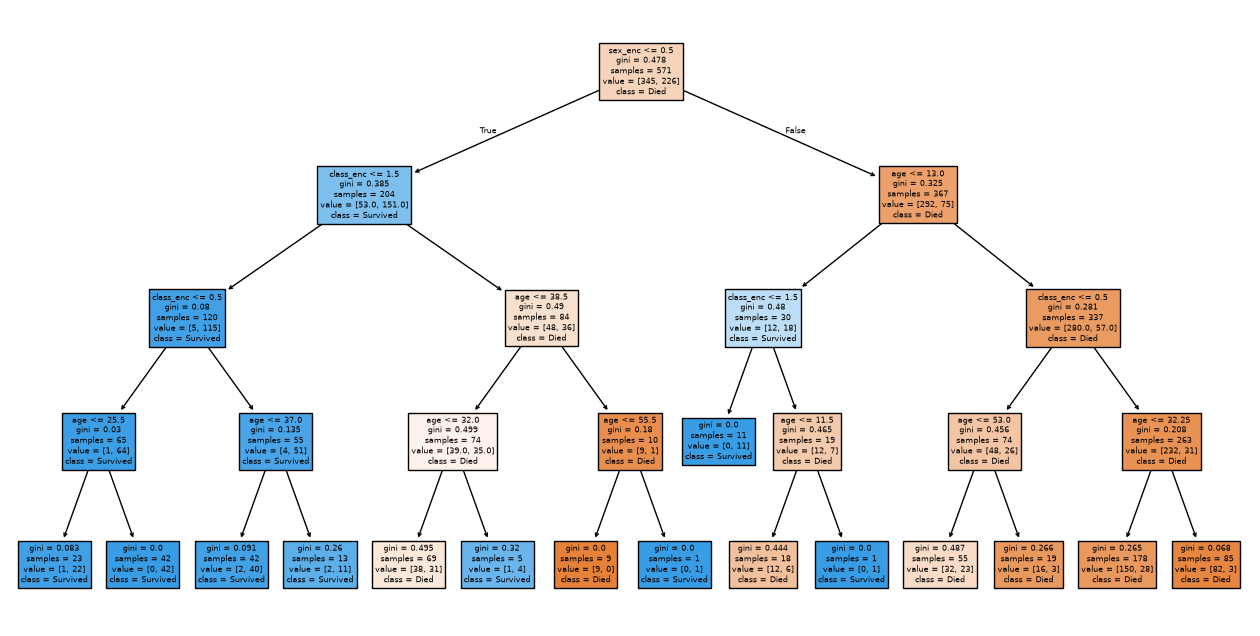

In [9]:
plt.figure(figsize=(16,8))
plot_tree(dt, feature_names=X.columns, class_names=['Died','Survived'], filled=True)
plt.show()

In [10]:
fi = pd.DataFrame({'Feature': X.columns, 'Importance': dt.feature_importances_})
fi

,Feature,Importance
0,sex_enc,0.555864
1,age,0.150418
2,class_enc,0.293718


## Part D: Reflection

In [11]:
# Part D reflection
print('Models like Naive Bayes and Decision Trees can reflect bias in the data, leading to unfair outcomes. Decision trees are interpretable, but they can overfit and be overconfident on limited or unbalanced data. Predictions are estimates, not guarantees. For non-technical audiences, use plain language, simple visuals, and confidence or probability wording to show uncertainty and limitations.')

Models like Naive Bayes and Decision Trees can reflect bias in the data, leading to unfair outcomes. Decision trees are interpretable, but they can overfit and be overconfident on limited or unbalanced data. Predictions are estimates, not guarantees. For non-technical audiences, use plain language, simple visuals, and confidence or probability wording to show uncertainty and limitations.
